In [ ]:
import itertools
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split

# ---------- settings ----------
N = 20                      # dimension: 20, 30 or 40
EPOCHS = 150
N_SEEDS = 5
DATA_DIR = Path("Datasets")
device = "mps" if torch.backends.mps.is_available(
) else "cpu"   # use "cpu" if MPS is slow

GRID = {
    "lr":     [3e-3, 1e-3, 3e-4],
    "wd":     [0, 1e-3, 1e-1],
    "p_drop": [0.0, 0.1],
    "inp":    ["raw", "sign"],
}
INPUTS = {"raw": lambda a: a, "sign": np.sign}

# ---------- data: 60% train / 20% val / 20% test ----------
X = np.load(DATA_DIR / f"kryptonite-{N}-X.npy")
y = np.load(DATA_DIR / f"kryptonite-{N}-y.npy")
Xtv, Xte, ytv, yte = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)
Xtr, Xva, ytr, yva = train_test_split(
    Xtv, ytv, test_size=0.25, random_state=0, stratify=ytv)

# ---------- model + training ----------


def make_mlp(d, width=256, depth=3, p_drop=0.0):
    layers, h = [], d
    for _ in range(depth):
        layers += [nn.Linear(h, width), nn.ReLU()]
        if p_drop > 0:
            layers.append(nn.Dropout(p_drop))
        h = width
    layers.append(nn.Linear(h, 1))
    return nn.Sequential(*layers)


def train(Xtr, ytr, Xval, yval, lr, wd=0.0, p_drop=0.0, width=256, depth=3,
          epochs=150, bs=256, seed=0):
    torch.manual_seed(seed)
    def f(a): return torch.tensor(a, dtype=torch.float32, device=device)
    Xtr_t, ytr_t, Xval_t, yval_t = f(Xtr), f(ytr), f(Xval), f(yval)
    model = make_mlp(Xtr.shape[1], width, depth, p_drop).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.BCEWithLogitsLoss()
    hist = {"train_acc": [], "val_acc": []}
    best = {"val_acc": 0.0, "state": None}

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss_fn(model(Xtr_t[idx]).squeeze(1), ytr_t[idx]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            for name, Xs, ys in [("train", Xtr_t, ytr_t), ("val", Xval_t, yval_t)]:
                out = model(Xs).squeeze(1)
                hist[f"{name}_acc"].append(
                    ((out > 0).float() == ys).float().mean().item())
        if hist["val_acc"][-1] > best["val_acc"]:
            best = {"val_acc": hist["val_acc"][-1],
                    "state": {k: v.clone() for k, v in model.state_dict().items()}}
    return hist, best


@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    out = model(torch.tensor(X, dtype=torch.float32, device=device)).squeeze(1)
    return float(((out > 0).cpu().numpy() == y).mean())


# ---------- 1) hyperparameter search, selected on VAL only ----------
records = []
for lr, wd, p, inp in itertools.product(*GRID.values()):
    f = INPUTS[inp]
    h, best = train(f(Xtr), ytr, f(Xva), yva, lr=lr,
                    wd=wd, p_drop=p, epochs=EPOCHS)
    records.append(dict(lr=lr, wd=wd, p_drop=p, inp=inp,
                   val=round(best["val_acc"], 3)))
    print(records[-1])

records.sort(key=lambda r: -r["val"])
cfg = records[0]
print("\nBest config on val:", cfg)

# ---------- 2) retrain best config over seeds, then score on TEST once ----------
f = INPUTS[cfg["inp"]]
test_accs = []
for seed in range(N_SEEDS):
    h, best = train(f(Xtr), ytr, f(Xva), yva, lr=cfg["lr"], wd=cfg["wd"],
                    p_drop=cfg["p_drop"], epochs=EPOCHS, seed=seed)
    model = make_mlp(Xtr.shape[1], 256, 3, cfg["p_drop"]).to(device)
    model.load_state_dict(best["state"])
    test_accs.append(accuracy(model, f(Xte), yte))
    print(f"seed {seed}: val {best['val_acc']:.3f}  test {test_accs[-1]:.3f}")

print(
    f"\nTEST accuracy (n={N}): {np.mean(test_accs):.3f} ± {np.std(test_accs):.3f}")

{'lr': 0.003, 'wd': 0, 'p_drop': 0.0, 'inp': 'raw', 'val': 0.933}
{'lr': 0.003, 'wd': 0, 'p_drop': 0.0, 'inp': 'sign', 'val': 0.938}
{'lr': 0.003, 'wd': 0, 'p_drop': 0.1, 'inp': 'raw', 'val': 0.946}
{'lr': 0.003, 'wd': 0, 'p_drop': 0.1, 'inp': 'sign', 'val': 0.952}
{'lr': 0.003, 'wd': 0.001, 'p_drop': 0.0, 'inp': 'raw', 'val': 0.924}
{'lr': 0.003, 'wd': 0.001, 'p_drop': 0.0, 'inp': 'sign', 'val': 0.937}
{'lr': 0.003, 'wd': 0.001, 'p_drop': 0.1, 'inp': 'raw', 'val': 0.95}
{'lr': 0.003, 'wd': 0.001, 'p_drop': 0.1, 'inp': 'sign', 'val': 0.954}
{'lr': 0.003, 'wd': 0.1, 'p_drop': 0.0, 'inp': 'raw', 'val': 0.945}
{'lr': 0.003, 'wd': 0.1, 'p_drop': 0.0, 'inp': 'sign', 'val': 0.94}
{'lr': 0.003, 'wd': 0.1, 'p_drop': 0.1, 'inp': 'raw', 'val': 0.95}
{'lr': 0.003, 'wd': 0.1, 'p_drop': 0.1, 'inp': 'sign', 'val': 0.95}
{'lr': 0.001, 'wd': 0, 'p_drop': 0.0, 'inp': 'raw', 'val': 0.882}
{'lr': 0.001, 'wd': 0, 'p_drop': 0.0, 'inp': 'sign', 'val': 0.925}
{'lr': 0.001, 'wd': 0, 'p_drop': 0.1, 'inp': 'raw

Device: mps
Dimension: 20
Dataset shape: (12000, 20)
Labels shape: (12000,)

Data split:
Train: (7200, 20)
Validation: (2400, 20)
Test: (2400, 20) (reserved)

ARCHITECTURE: 64-64-64
Layer sizes: (64, 64, 64)
Seed 0: Val=0.9604 | Best epoch=87
Seed 1: Val=0.9579 | Best epoch=82
Seed 2: Val=0.9604 | Best epoch=74
Seed 3: Val=0.9629 | Best epoch=97
Seed 4: Val=0.9604 | Best epoch=36

ARCHITECTURE: 128-128-128
Layer sizes: (128, 128, 128)
Seed 0: Val=0.9542 | Best epoch=30
Seed 1: Val=0.9538 | Best epoch=43
Seed 2: Val=0.9554 | Best epoch=22
Seed 3: Val=0.9525 | Best epoch=38
Seed 4: Val=0.9533 | Best epoch=69

ARCHITECTURE: 256-256-256
Layer sizes: (256, 256, 256)
Seed 0: Val=0.9538 | Best epoch=26
Seed 1: Val=0.9542 | Best epoch=48
Seed 2: Val=0.9513 | Best epoch=148
Seed 3: Val=0.9479 | Best epoch=134
Seed 4: Val=0.9533 | Best epoch=107

ARCHITECTURE: 256-128-64
Layer sizes: (256, 128, 64)
Seed 0: Val=0.9538 | Best epoch=114
Seed 1: Val=0.9550 | Best epoch=25
Seed 2: Val=0.9517 | Best e

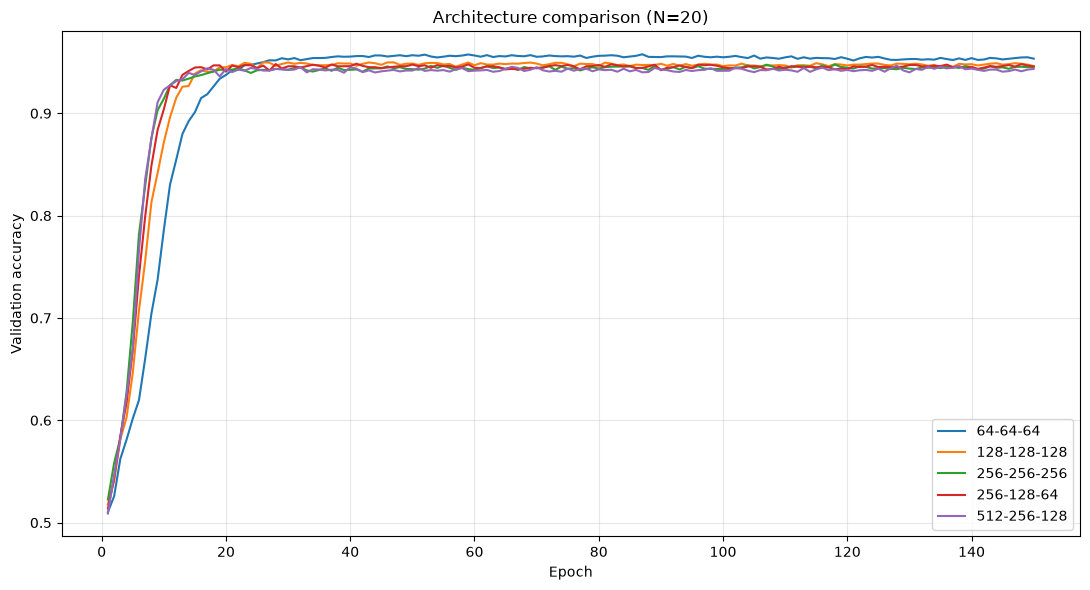

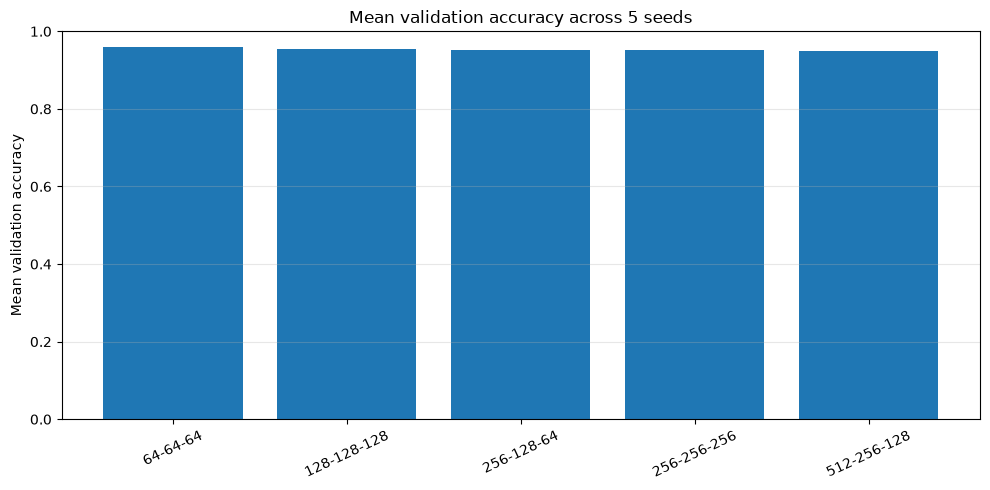


BEST ARCHITECTURE:
Name: 64-64-64
Parameters: 9729
Mean validation: 0.9604
Std deviation: 0.0016

Test set has NOT been used.


In [5]:
import copy
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split

# ============================================================
# 1. SETTINGS
# ============================================================

N = 20
EPOCHS = 150
N_SEEDS = 5
BATCH_SIZE = 256

DATA_DIR = Path("Datasets")

LR = 0.003
WEIGHT_DECAY = 0.001
P_DROP = 0.1

device = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)
print("Dimension:", N)

# ============================================================
# 2. ARCHITECTURES
# ============================================================

ARCHITECTURES = {
    "64-64-64":       (64, 64, 64),
    "128-128-128":    (128, 128, 128),
    "256-256-256":    (256, 256, 256),
    "256-128-64":     (256, 128, 64),
    "512-256-128":    (512, 256, 128),
}

# ============================================================
# 3. LOAD DATA
# ============================================================

X = np.load(DATA_DIR / f"kryptonite-{N}-X.npy")
y = np.load(DATA_DIR / f"kryptonite-{N}-y.npy")

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)

# 60% train / 20% validation / 20% test

Xtv, Xte, ytv, yte = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

Xtr, Xva, ytr, yva = train_test_split(
    Xtv,
    ytv,
    test_size=0.25,
    random_state=0,
    stratify=ytv
)

# Sign transformation
Xtr = np.sign(Xtr).astype(np.float32)
Xva = np.sign(Xva).astype(np.float32)

ytr = ytr.astype(np.float32)
yva = yva.astype(np.float32)

print("\nData split:")
print("Train:", Xtr.shape)
print("Validation:", Xva.shape)
print("Test:", Xte.shape, "(reserved)")

# ============================================================
# 4. MODEL
# ============================================================


def make_mlp(d, widths, p_drop=0.1):

    layers = []
    h = d

    for width in widths:

        layers.extend([
            nn.Linear(h, width),
            nn.ReLU(),
            nn.Dropout(p_drop)
        ])

        h = width

    layers.append(nn.Linear(h, 1))

    return nn.Sequential(*layers)


def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

# ============================================================
# 5. TRAINING FUNCTION
# ============================================================


def train(
    Xtr,
    ytr,
    Xval,
    yval,
    widths,
    lr=LR,
    wd=WEIGHT_DECAY,
    p_drop=P_DROP,
    epochs=EPOCHS,
    bs=BATCH_SIZE,
    seed=0
):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if device == "mps":
        torch.mps.manual_seed(seed)
    elif device == "cuda":
        torch.cuda.manual_seed_all(seed)

    def f(a): return torch.tensor(
        a,
        dtype=torch.float32,
        device=device
    )

    Xtr_t = f(Xtr)
    ytr_t = f(ytr)

    Xval_t = f(Xval)
    yval_t = f(yval)

    model = make_mlp(
        Xtr.shape[1],
        widths,
        p_drop
    ).to(device)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=wd
    )

    loss_fn = nn.BCEWithLogitsLoss()

    history = {
        "train_acc": [],
        "val_acc": [],
        "train_loss": []
    }

    best = {
        "val_acc": -1.0,
        "epoch": 0,
        "state": None
    }

    for ep in range(epochs):

        model.train()

        perm = torch.randperm(
            len(Xtr_t),
            device=device
        )

        epoch_loss = 0.0

        for i in range(0, len(perm), bs):

            idx = perm[i:i + bs]

            opt.zero_grad()

            logits = model(Xtr_t[idx]).squeeze(1)

            loss = loss_fn(logits, ytr_t[idx])

            loss.backward()
            opt.step()

            epoch_loss += loss.item() * len(idx)

        model.eval()

        with torch.no_grad():

            train_out = model(Xtr_t).squeeze(1)
            val_out = model(Xval_t).squeeze(1)

            train_acc = (
                ((train_out > 0).float() == ytr_t)
                .float()
                .mean()
                .item()
            )

            val_acc = (
                ((val_out > 0).float() == yval_t)
                .float()
                .mean()
                .item()
            )

        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["train_loss"].append(
            epoch_loss / len(Xtr_t)
        )

        if val_acc > best["val_acc"]:

            best = {
                "val_acc": val_acc,
                "epoch": ep + 1,
                "state": copy.deepcopy(model.state_dict())
            }

    return history, best, count_parameters(model)

# ============================================================
# 6. RUN ALL ARCHITECTURES
# ============================================================


results = {}
histories = {}

for name, widths in ARCHITECTURES.items():

    print("\n" + "=" * 55)
    print("ARCHITECTURE:", name)
    print("Layer sizes:", widths)
    print("=" * 55)

    seed_scores = []
    seed_epochs = []
    architecture_histories = []

    for seed in range(N_SEEDS):

        history, best, params = train(
            Xtr,
            ytr,
            Xva,
            yva,
            widths=widths,
            seed=seed
        )

        seed_scores.append(best["val_acc"])
        seed_epochs.append(best["epoch"])
        architecture_histories.append(history)

        print(
            f"Seed {seed}: "
            f"Val={best['val_acc']:.4f} | "
            f"Best epoch={best['epoch']}"
        )

    results[name] = {
        "widths": widths,
        "mean_val": np.mean(seed_scores),
        "std_val": np.std(seed_scores),
        "scores": seed_scores,
        "mean_epoch": np.mean(seed_epochs),
        "parameters": params
    }

    histories[name] = architecture_histories

# ============================================================
# 7. RESULTS TABLE
# ============================================================

rows = []

for name, r in results.items():

    rows.append({
        "Architecture": name,
        "Parameters": r["parameters"],
        "Mean validation": r["mean_val"],
        "Std deviation": r["std_val"],
        "Mean best epoch": r["mean_epoch"]
    })

df = pd.DataFrame(rows)

df = df.sort_values(
    "Mean validation",
    ascending=False
).reset_index(drop=True)

print("\nFINAL ARCHITECTURE COMPARISON")
print(df.to_string(index=False))

# Save results
df.to_csv(
    f"architecture_results_N{N}.csv",
    index=False
)

# ============================================================
# 8. PLOT VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(11, 6))

for name, architecture_histories in histories.items():

    # Average validation curve across seeds
    curves = np.array([
        h["val_acc"]
        for h in architecture_histories
    ])

    mean_curve = curves.mean(axis=0)

    plt.plot(
        range(1, EPOCHS + 1),
        mean_curve,
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title(f"Architecture comparison (N={N})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 9. PLOT MEAN ACCURACY
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    df["Architecture"],
    df["Mean validation"]
)

plt.ylabel("Mean validation accuracy")
plt.title(f"Mean validation accuracy across {N_SEEDS} seeds")
plt.xticks(rotation=25)
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 10. BEST ARCHITECTURE
# ============================================================

winner = df.iloc[0]

print("\nBEST ARCHITECTURE:")
print("Name:", winner["Architecture"])
print("Parameters:", int(winner["Parameters"]))
print("Mean validation:", round(winner["Mean validation"], 4))
print("Std deviation:", round(winner["Std deviation"], 4))

print("\nTest set has NOT been used.")


ARCHITECTURE: D: 64-64-64-64
Layer sizes: (64, 64, 64, 64)
Seed 0: Val=0.9604 | Best epoch=122
Seed 1: Val=0.9604 | Best epoch=80
Seed 2: Val=0.9608 | Best epoch=47
Seed 3: Val=0.9596 | Best epoch=47
Seed 4: Val=0.9592 | Best epoch=73

ARCHITECTURE: E: 32-32-32-32-32-32
Layer sizes: (32, 32, 32, 32, 32, 32)
Seed 0: Val=0.9600 | Best epoch=149
Seed 1: Val=0.9625 | Best epoch=80
Seed 2: Val=0.9604 | Best epoch=86
Seed 3: Val=0.9546 | Best epoch=65
Seed 4: Val=0.9600 | Best epoch=60

ARCHITECTURE: F: 128-64-32-16
Layer sizes: (128, 64, 32, 16)
Seed 0: Val=0.9558 | Best epoch=76
Seed 1: Val=0.9567 | Best epoch=146
Seed 2: Val=0.9579 | Best epoch=123
Seed 3: Val=0.9463 | Best epoch=145
Seed 4: Val=0.9550 | Best epoch=84

DEEP ARCHITECTURE COMPARISON
        Architecture  Parameters  Mean validation  Std deviation  Mean best epoch
      D: 64-64-64-64       13889         0.960083       0.000612             73.8
E: 32-32-32-32-32-32        5985         0.959500       0.002627             88.

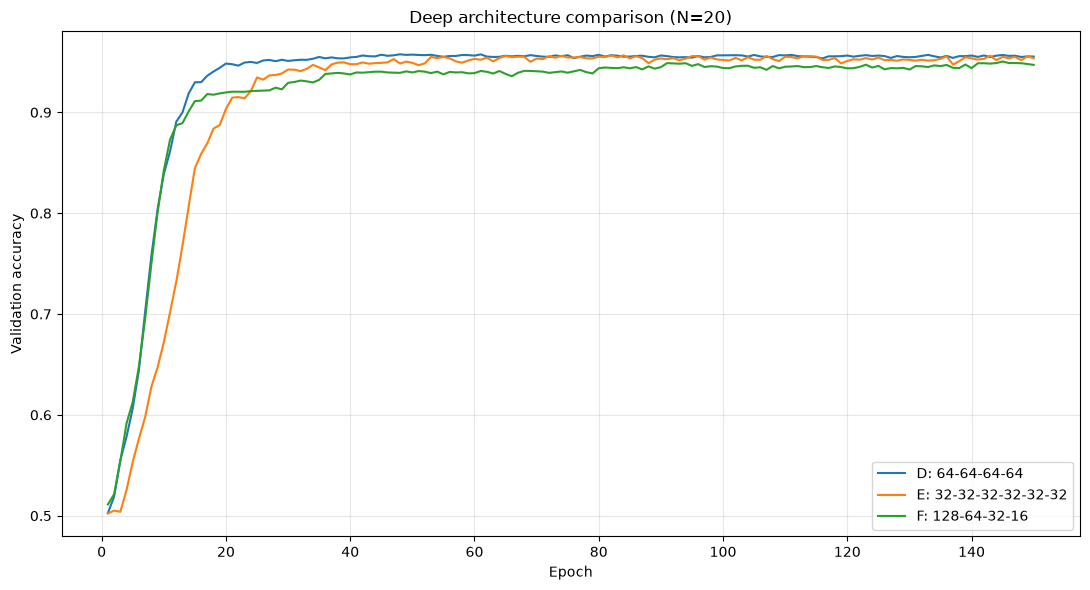


BEST DEEP ARCHITECTURE:
Name: D: 64-64-64-64
Parameters: 13889
Mean validation: 0.9601
Std deviation: 0.0006


In [6]:
# ============================================================
# TEST DEEPER ARCHITECTURES D, E AND F
# ============================================================

DEEP_ARCHITECTURES = {
    "D: 64-64-64-64":          (64, 64, 64, 64),
    "E: 32-32-32-32-32-32":    (32, 32, 32, 32, 32, 32),
    "F: 128-64-32-16":         (128, 64, 32, 16),
}

deep_results = {}
deep_histories = {}

for name, widths in DEEP_ARCHITECTURES.items():

    print("\n" + "=" * 55)
    print("ARCHITECTURE:", name)
    print("Layer sizes:", widths)
    print("=" * 55)

    seed_scores = []
    seed_epochs = []
    architecture_histories = []

    for seed in range(N_SEEDS):

        history, best, params = train(
            Xtr,
            ytr,
            Xva,
            yva,
            widths=widths,
            seed=seed
        )

        seed_scores.append(best["val_acc"])
        seed_epochs.append(best["epoch"])
        architecture_histories.append(history)

        print(
            f"Seed {seed}: "
            f"Val={best['val_acc']:.4f} | "
            f"Best epoch={best['epoch']}"
        )

    deep_results[name] = {
        "widths": widths,
        "mean_val": np.mean(seed_scores),
        "std_val": np.std(seed_scores),
        "scores": seed_scores,
        "mean_epoch": np.mean(seed_epochs),
        "parameters": params
    }

    deep_histories[name] = architecture_histories


# ============================================================
# RESULTS TABLE
# ============================================================

deep_rows = []

for name, r in deep_results.items():

    deep_rows.append({
        "Architecture": name,
        "Parameters": r["parameters"],
        "Mean validation": r["mean_val"],
        "Std deviation": r["std_val"],
        "Mean best epoch": r["mean_epoch"]
    })

deep_df = pd.DataFrame(deep_rows)

deep_df = deep_df.sort_values(
    "Mean validation",
    ascending=False
).reset_index(drop=True)

print("\nDEEP ARCHITECTURE COMPARISON")
print(deep_df.to_string(index=False))


# ============================================================
# PLOT VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(11, 6))

for name, architecture_histories in deep_histories.items():

    curves = np.array([
        h["val_acc"]
        for h in architecture_histories
    ])

    plt.plot(
        range(1, EPOCHS + 1),
        curves.mean(axis=0),
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title(f"Deep architecture comparison (N={N})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# BEST DEEP ARCHITECTURE
# ============================================================

winner = deep_df.iloc[0]

print("\nBEST DEEP ARCHITECTURE:")
print("Name:", winner["Architecture"])
print("Parameters:", int(winner["Parameters"]))
print("Mean validation:", round(winner["Mean validation"], 4))
print("Std deviation:", round(winner["Std deviation"], 4))


ARCHITECTURE: 16-16
Layer sizes: (16, 16)
Seed 0: Val=0.8988 | Best epoch=128
Seed 1: Val=0.8846 | Best epoch=142
Seed 2: Val=0.9021 | Best epoch=131
Seed 3: Val=0.9092 | Best epoch=144
Seed 4: Val=0.8838 | Best epoch=113

ARCHITECTURE: 32-32
Layer sizes: (32, 32)
Seed 0: Val=0.9563 | Best epoch=150
Seed 1: Val=0.9513 | Best epoch=148
Seed 2: Val=0.9500 | Best epoch=133
Seed 3: Val=0.9479 | Best epoch=127
Seed 4: Val=0.9450 | Best epoch=112

ARCHITECTURE: 32-32-32
Layer sizes: (32, 32, 32)
Seed 0: Val=0.9583 | Best epoch=119
Seed 1: Val=0.9579 | Best epoch=111
Seed 2: Val=0.9596 | Best epoch=136
Seed 3: Val=0.9592 | Best epoch=146
Seed 4: Val=0.9604 | Best epoch=150

ARCHITECTURE: 64-32
Layer sizes: (64, 32)
Seed 0: Val=0.9558 | Best epoch=105
Seed 1: Val=0.9504 | Best epoch=107
Seed 2: Val=0.9533 | Best epoch=128
Seed 3: Val=0.9538 | Best epoch=113
Seed 4: Val=0.9546 | Best epoch=143

ARCHITECTURE: 64-32-16
Layer sizes: (64, 32, 16)
Seed 0: Val=0.9583 | Best epoch=123
Seed 1: Val=0.9

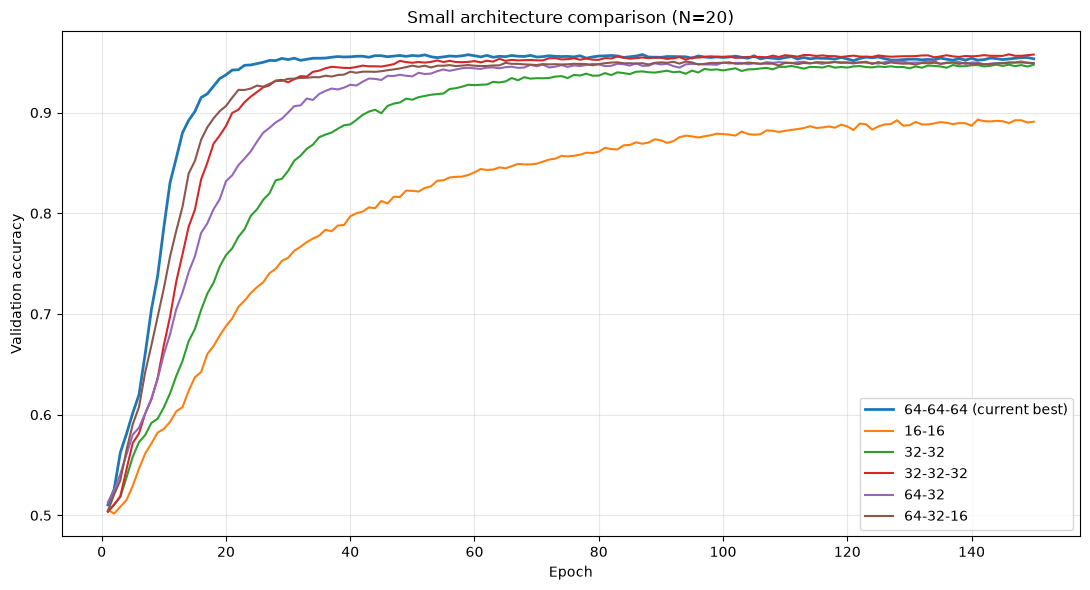


BEST SMALL ARCHITECTURE:
Name: 32-32-32
Parameters: 2817
Mean validation: 0.9591
Std deviation: 0.0009

CURRENT BEST: 64-64-64
Parameters: 9729
Mean validation: 0.9604

Test set has NOT been used.


In [7]:

# ============================================================
# TEST SMALLER ARCHITECTURES
# ============================================================

SMALL_ARCHITECTURES = {
    "16-16":          (16, 16),
    "32-32":          (32, 32),
    "32-32-32":       (32, 32, 32),
    "64-32":          (64, 32),
    "64-32-16":       (64, 32, 16),
}

small_results = {}
small_histories = {}

for name, widths in SMALL_ARCHITECTURES.items():

    print("\n" + "=" * 55)
    print("ARCHITECTURE:", name)
    print("Layer sizes:", widths)
    print("=" * 55)

    seed_scores = []
    seed_epochs = []
    architecture_histories = []

    for seed in range(N_SEEDS):

        history, best, params = train(
            Xtr,
            ytr,
            Xva,
            yva,
            widths=widths,
            seed=seed
        )

        seed_scores.append(best["val_acc"])
        seed_epochs.append(best["epoch"])
        architecture_histories.append(history)

        print(
            f"Seed {seed}: "
            f"Val={best['val_acc']:.4f} | "
            f"Best epoch={best['epoch']}"
        )

    small_results[name] = {
        "widths": widths,
        "mean_val": np.mean(seed_scores),
        "std_val": np.std(seed_scores),
        "scores": seed_scores,
        "mean_epoch": np.mean(seed_epochs),
        "parameters": params
    }

    small_histories[name] = architecture_histories


# ============================================================
# RESULTS TABLE
# ============================================================

small_rows = []

for name, r in small_results.items():

    small_rows.append({
        "Architecture": name,
        "Parameters": r["parameters"],
        "Mean validation": r["mean_val"],
        "Std deviation": r["std_val"],
        "Mean best epoch": r["mean_epoch"]
    })

small_df = pd.DataFrame(small_rows)

small_df = small_df.sort_values(
    "Mean validation",
    ascending=False
).reset_index(drop=True)

print("\nSMALL ARCHITECTURE COMPARISON")
print(small_df.to_string(index=False))


# ============================================================
# COMPARE ALL ARCHITECTURES TESTED SO FAR
# ============================================================

combined_df = pd.concat(
    [df, deep_df, small_df],
    ignore_index=True
)

combined_df = combined_df.sort_values(
    "Mean validation",
    ascending=False
).reset_index(drop=True)

print("\nCOMPLETE ARCHITECTURE RANKING")
print(combined_df.to_string(index=False))


# ============================================================
# PLOT SMALL NETWORKS AGAINST CURRENT BEST
# ============================================================

plt.figure(figsize=(11, 6))

# Existing best architecture: 64-64-64
baseline_curves = np.array([
    h["val_acc"]
    for h in histories["64-64-64"]
])

plt.plot(
    range(1, EPOCHS + 1),
    baseline_curves.mean(axis=0),
    label="64-64-64 (current best)",
    linewidth=2
)

# New smaller architectures
for name, architecture_histories in small_histories.items():

    curves = np.array([
        h["val_acc"]
        for h in architecture_histories
    ])

    plt.plot(
        range(1, EPOCHS + 1),
        curves.mean(axis=0),
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title(f"Small architecture comparison (N={N})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# BEST SMALL ARCHITECTURE
# ============================================================

winner = small_df.iloc[0]

print("\nBEST SMALL ARCHITECTURE:")
print("Name:", winner["Architecture"])
print("Parameters:", int(winner["Parameters"]))
print("Mean validation:", round(winner["Mean validation"], 4))
print("Std deviation:", round(winner["Std deviation"], 4))

print("\nCURRENT BEST: 64-64-64")
print("Parameters:", results["64-64-64"]["parameters"])
print("Mean validation:", round(results["64-64-64"]["mean_val"], 4))

print("\nTest set has NOT been used.")


In [8]:

# ============================================================
# 5-FOLD STRATIFIED CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import StratifiedKFold

CV_ARCHITECTURES = {
    "64-64-64": (64, 64, 64),
    "32-32-32": (32, 32, 32),
    "32-32-32-32-32-32": (32, 32, 32, 32, 32, 32),
    "64-64-64-64": (64, 64, 64, 64),
}

N_FOLDS = 5
CV_SEEDS = range(5)

# Combine existing training and validation data.
# The original test set is NOT included.

X_dev = np.concatenate([Xtr, Xva], axis=0)
y_dev = np.concatenate([ytr.reshape(-1), yva.reshape(-1)])

print("Development dataset:", X_dev.shape)
print("Test dataset remains untouched:", Xte.shape)

# Create stratified folds
skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=0
)

cv_results = {}

# ============================================================
# RUN CROSS-VALIDATION
# ============================================================

for name, widths in CV_ARCHITECTURES.items():

    print("\n" + "=" * 60)
    print("ARCHITECTURE:", name)
    print("Layer sizes:", widths)
    print("=" * 60)

    fold_scores = []
    all_scores = []
    fold_epochs = []
    params = None

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_dev, y_dev.astype(int)), start=1
    ):

        X_fold_train = X_dev[train_idx]
        y_fold_train = y_dev[train_idx]

        X_fold_val = X_dev[val_idx]
        y_fold_val = y_dev[val_idx]

        seed_scores = []
        seed_epochs = []

        print(f"\nFold {fold}/{N_FOLDS}")

        for seed in CV_SEEDS:

            history, best, params = train(
                X_fold_train,
                y_fold_train,
                X_fold_val,
                y_fold_val,
                widths=widths,
                seed=seed
            )

            seed_scores.append(best["val_acc"])
            seed_epochs.append(best["epoch"])
            all_scores.append(best["val_acc"])

            print(
                f"Seed {seed}: "
                f"Val={best['val_acc']:.4f} | "
                f"Best epoch={best['epoch']}"
            )

        fold_mean = np.mean(seed_scores)

        fold_scores.append(fold_mean)
        fold_epochs.extend(seed_epochs)

        print(f"Fold mean: {fold_mean:.4f}")

    cv_results[name] = {
        "widths": widths,
        "parameters": params,
        "fold_scores": fold_scores,
        "mean_cv": np.mean(fold_scores),
        "std_folds": np.std(fold_scores),
        "std_runs": np.std(all_scores),
        "mean_epoch": np.mean(fold_epochs)
    }


# ============================================================
# RESULTS TABLE
# ============================================================

cv_rows = []

for name, r in cv_results.items():

    cv_rows.append({
        "Architecture": name,
        "Parameters": r["parameters"],
        "Mean CV accuracy": r["mean_cv"],
        "Fold std": r["std_folds"],
        "Run std": r["std_runs"],
        "Mean best epoch": r["mean_epoch"]
    })

cv_df = pd.DataFrame(cv_rows)

cv_df = cv_df.sort_values(
    "Mean CV accuracy",
    ascending=False
).reset_index(drop=True)

print("\nFINAL CROSS-VALIDATION RESULTS")
print(cv_df.to_string(index=False))

print("\nBest architecture:")
print(cv_df.iloc[0].to_string())

print("\nOriginal test set has NOT been used.")


Development dataset: (9600, 20)
Test dataset remains untouched: (2400, 20)

ARCHITECTURE: 64-64-64
Layer sizes: (64, 64, 64)

Fold 1/5
Seed 0: Val=0.9500 | Best epoch=113
Seed 1: Val=0.9516 | Best epoch=108
Seed 2: Val=0.9490 | Best epoch=81
Seed 3: Val=0.9526 | Best epoch=57
Seed 4: Val=0.9521 | Best epoch=73
Fold mean: 0.9510

Fold 2/5
Seed 0: Val=0.9604 | Best epoch=36
Seed 1: Val=0.9573 | Best epoch=95
Seed 2: Val=0.9583 | Best epoch=80
Seed 3: Val=0.9589 | Best epoch=79
Seed 4: Val=0.9594 | Best epoch=35
Fold mean: 0.9589

Fold 3/5
Seed 0: Val=0.9573 | Best epoch=60
Seed 1: Val=0.9589 | Best epoch=67
Seed 2: Val=0.9573 | Best epoch=72
Seed 3: Val=0.9594 | Best epoch=38
Seed 4: Val=0.9589 | Best epoch=25
Fold mean: 0.9583

Fold 4/5
Seed 0: Val=0.9510 | Best epoch=31
Seed 1: Val=0.9490 | Best epoch=31
Seed 2: Val=0.9505 | Best epoch=115
Seed 3: Val=0.9495 | Best epoch=58
Seed 4: Val=0.9510 | Best epoch=42
Fold mean: 0.9502

Fold 5/5
Seed 0: Val=0.9557 | Best epoch=73
Seed 1: Val=0.9

In [13]:
# Test single-hidden-layer neural networks

ONE_LAYER_ARCHITECTURES = {
    "1-layer-32": (32,),
    "1-layer-64": (64,),
    "1-layer-128": (128,),
}

one_layer_results = []
one_layer_checkpoints = {}

for arch_name, widths in ONE_LAYER_ARCHITECTURES.items():
    seed_val_accs = []
    seed_best_epochs = []

    for seed in range(N_SEEDS):
        model, best_checkpoint, best_epoch = train(
            Xtr, ytr,
            Xva, yva,
            widths=widths,
            seed=seed
        )

        best_val_acc = best_checkpoint["val_acc"]

        seed_val_accs.append(best_val_acc)
        seed_best_epochs.append(best_epoch)

        one_layer_checkpoints[(arch_name, seed)] = best_checkpoint

    # Calculate number of trainable parameters
    model = make_mlp(Xtr.shape[1], widths, p_drop=P_DROP)
    n_params = sum(p.numel() for p in model.parameters())

    one_layer_results.append({
        "architecture": arch_name,
        "parameters": n_params,
        "mean_val_acc": np.mean(seed_val_accs),
        "std_val_acc": np.std(seed_val_accs),
        "mean_best_epoch": np.mean(seed_best_epochs),
    })

one_layer_df = pd.DataFrame(one_layer_results)

one_layer_df = one_layer_df.sort_values(
    "mean_val_acc",
    ascending=False
).reset_index(drop=True)

print(one_layer_df.to_string(index=False))

architecture  parameters  mean_val_acc  std_val_acc  mean_best_epoch
 1-layer-128        2817      0.817083     0.012564           2817.0
  1-layer-64        1409      0.774417     0.007503           1409.0
  1-layer-32         705      0.726667     0.011923            705.0


In [15]:
# Final evaluation on held-out test set

FINAL_ARCHITECTURE = (32, 32, 32)

test_accuracies = []

X_test_tensor = torch.tensor(
    np.sign(Xte).astype(np.float32),
    dtype=torch.float32,
    device=device
)

y_test_tensor = torch.tensor(
    yte,
    dtype=torch.float32,
    device=device
).view(-1, 1)

for seed in range(N_SEEDS):

    _, best_checkpoint, best_epoch = train(
        Xtr, ytr,
        Xva, yva,
        widths=FINAL_ARCHITECTURE,
        seed=seed
    )

    # Recreate model and load best validation checkpoint
    model = make_mlp(
        Xtr.shape[1],
        FINAL_ARCHITECTURE,
        p_drop=P_DROP
    ).to(device)

    model.load_state_dict(best_checkpoint["state"])
    model.eval()

    # Evaluate on held-out test set
    with torch.no_grad():
        logits = model(X_test_tensor)
        predictions = (torch.sigmoid(logits) >= 0.5).float()

        test_acc = (
            predictions == y_test_tensor
        ).float().mean().item()

    test_accuracies.append(test_acc)

    print(
        f"Seed {seed}: Test accuracy = {test_acc:.4f} | "
        f"Best epoch = {best_epoch}"
    )

print("\nFINAL TEST RESULTS")
print(f"Mean test accuracy: {np.mean(test_accuracies):.4f}")
print(f"Std test accuracy:  {np.std(test_accuracies):.4f}")

Seed 0: Test accuracy = 0.9521 | Best epoch = 2817
Seed 1: Test accuracy = 0.9496 | Best epoch = 2817
Seed 2: Test accuracy = 0.9517 | Best epoch = 2817
Seed 3: Test accuracy = 0.9508 | Best epoch = 2817
Seed 4: Test accuracy = 0.9521 | Best epoch = 2817

FINAL TEST RESULTS
Mean test accuracy: 0.9513
Std test accuracy:  0.0010


Device: mps

KRYPTONITE-30
Training: (12000, 30)
Validation: (4000, 30)
Testing: (4000, 30)
Seed 0: Val=0.9553 | Test=0.9585 | Best epoch=68
Seed 1: Val=0.9565 | Test=0.9583 | Best epoch=120
Seed 2: Val=0.9560 | Test=0.9593 | Best epoch=122
Seed 3: Val=0.9563 | Test=0.9573 | Best epoch=74
Seed 4: Val=0.9475 | Test=0.9490 | Best epoch=42

KRYPTONITE-40
Training: (19200, 40)
Validation: (6400, 40)
Testing: (6400, 40)
Seed 0: Val=0.9616 | Test=0.9534 | Best epoch=51
Seed 1: Val=0.9642 | Test=0.9564 | Best epoch=83
Seed 2: Val=0.9505 | Test=0.9461 | Best epoch=69
Seed 3: Val=0.9641 | Test=0.9547 | Best epoch=137
Seed 4: Val=0.9644 | Test=0.9552 | Best epoch=127

INDIVIDUAL RESULTS
 dataset  seed  val_accuracy  test_accuracy  best_epoch  parameters
      30     0      0.955250       0.958500          68        3137
      30     1      0.956500       0.958250         120        3137
      30     2      0.956000       0.959250         122        3137
      30     3      0.956250       0.95725

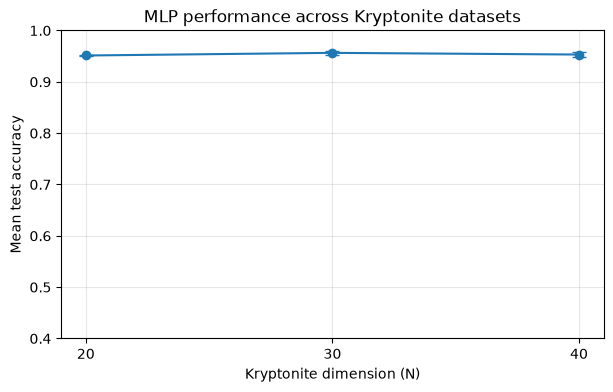

In [16]:

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import pandas as pd
import matplotlib.pyplot as plt
import random
import copy

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

DEVICE = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

EPOCHS = 150
N_SEEDS = 5
BATCH_SIZE = 256

LEARNING_RATE = 0.003
WEIGHT_DECAY = 0.001
DROPOUT = 0.1
HIDDEN_WIDTHS = (32, 32, 32)

print("Device:", DEVICE)


# --------------------------------------------------
# 2. Model architecture
# --------------------------------------------------

def make_mlp(d):
    layers = []
    h = d

    for width in HIDDEN_WIDTHS:
        layers.extend([
            nn.Linear(h, width),
            nn.ReLU(),
            nn.Dropout(DROPOUT)
        ])
        h = width

    layers.append(nn.Linear(h, 1))
    return nn.Sequential(*layers)


# --------------------------------------------------
# 3. Reproducibility
# --------------------------------------------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# --------------------------------------------------
# 4. Evaluation
# --------------------------------------------------

def get_accuracy(model, X, y):
    model.eval()

    with torch.no_grad():
        X_tensor = torch.tensor(
            X, dtype=torch.float32, device=DEVICE
        )
        logits = model(X_tensor).squeeze(1)
        predictions = (logits > 0).cpu().numpy()

    return accuracy_score(y, predictions)


# --------------------------------------------------
# 5. Training
# --------------------------------------------------

def train_mlp(X_train, y_train, X_val, y_val, seed):
    set_seed(seed)

    model = make_mlp(X_train.shape[1]).to(DEVICE)

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32)
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    optimiser = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    criterion = nn.BCEWithLogitsLoss()

    best_val_acc = 0
    best_epoch = 0
    best_state = None

    for epoch in range(EPOCHS):
        model.train()

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimiser.zero_grad()

            logits = model(xb).squeeze(1)
            loss = criterion(logits, yb)

            loss.backward()
            optimiser.step()

        val_acc = get_accuracy(model, X_val, y_val)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)

    return model, best_val_acc, best_epoch


# --------------------------------------------------
# 6. Run experiments on N=30 and N=40
# --------------------------------------------------

all_results = []

for n in [30, 40]:

    print(f"\n{'='*45}")
    print(f"KRYPTONITE-{n}")
    print(f"{'='*45}")

    # Load data
    X = np.load(f"Datasets/kryptonite-{n}-X.npy")
    y = np.load(f"Datasets/kryptonite-{n}-y.npy")

    # Same preprocessing as N=20
    X = np.sign(X).astype(np.float32)
    y = y.astype(np.float32).reshape(-1)

    # 60/20/20 stratified split
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y,
        test_size=0.4,
        random_state=0,
        stratify=y
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp,
        test_size=0.5,
        random_state=0,
        stratify=y_temp
    )

    print("Training:", X_train.shape)
    print("Validation:", X_val.shape)
    print("Testing:", X_test.shape)

    # Five random seeds
    for seed in range(N_SEEDS):

        model, val_acc, best_epoch = train_mlp(
            X_train, y_train,
            X_val, y_val,
            seed
        )

        test_acc = get_accuracy(model, X_test, y_test)

        n_params = sum(
            p.numel() for p in model.parameters()
            if p.requires_grad
        )

        all_results.append({
            "dataset": n,
            "seed": seed,
            "val_accuracy": val_acc,
            "test_accuracy": test_acc,
            "best_epoch": best_epoch,
            "parameters": n_params
        })

        print(
            f"Seed {seed}: "
            f"Val={val_acc:.4f} | "
            f"Test={test_acc:.4f} | "
            f"Best epoch={best_epoch}"
        )


# --------------------------------------------------
# 7. Individual results
# --------------------------------------------------

results_df = pd.DataFrame(all_results)

print("\nINDIVIDUAL RESULTS")
print(results_df.to_string(index=False))


# --------------------------------------------------
# 8. Summary statistics
# --------------------------------------------------

summary = results_df.groupby("dataset").agg(
    mean_val_accuracy=("val_accuracy", "mean"),
    std_val_accuracy=("val_accuracy", "std"),
    mean_test_accuracy=("test_accuracy", "mean"),
    std_test_accuracy=("test_accuracy", "std"),
    mean_best_epoch=("best_epoch", "mean"),
    parameters=("parameters", "first")
).reset_index()

print("\nSUMMARY RESULTS")
print(summary.to_string(index=False))


# --------------------------------------------------
# 9. Comparison with existing N=20 results
# --------------------------------------------------

comparison = pd.DataFrame([
    {
        "dataset": 20,
        "mean_test_accuracy": 0.9513,
        "std_test_accuracy": 0.0010,
        "parameters": 2817
    }
])

comparison = pd.concat([
    comparison,
    summary[[
        "dataset",
        "mean_test_accuracy",
        "std_test_accuracy",
        "parameters"
    ]]
], ignore_index=True)

print("\nCOMPARISON ACROSS DATASETS")
print(comparison.to_string(index=False))


# --------------------------------------------------
# 10. Plot
# --------------------------------------------------

plt.figure(figsize=(7, 4))

plt.errorbar(
    comparison["dataset"],
    comparison["mean_test_accuracy"],
    yerr=comparison["std_test_accuracy"],
    marker="o",
    capsize=5
)

plt.xlabel("Kryptonite dimension (N)")
plt.ylabel("Mean test accuracy")
plt.title("MLP performance across Kryptonite datasets")
plt.xticks([20, 30, 40])
plt.ylim(0.4, 1.0)
plt.grid(alpha=0.3)
plt.show()
